# Exercise: Can an encoder tell blood cells apart?

Each image is one blood cell. There are **8 types** of cell, like `neutrophil`, `lymphocyte`, and `platelet`. Doctors count these types to check a patient's health.

We used a pretrained encoder, [CLIP](https://huggingface.co/openai/clip-vit-base-patch32) from OpenAI, to turn each image into a row of 512 numbers. It is the same encoder as in lecture 17. Your job is to fit a model on those numbers and see how well it names the cell type.

> Aside: The images come from [BloodMNIST](https://medmnist.com/), a set of small blood cell photos.

## Setup

In [1]:
library('tidymodels')
library('embed')

options(repr.plot.res = 250, repr.plot.height = 3, repr.plot.width = 5)

── Attaching packages ─────────────────────────────────────────────────────────────────────────────────────────────── tidymodels 1.4.1 ──
✔ broom        1.0.13     ✔ recipes      1.4.0 
✔ dials        1.4.4      ✔ rsample      1.3.2 
✔ dplyr        1.2.1      ✔ tailor       0.1.0 
✔ ggplot2      4.0.3      ✔ tidyr        1.3.2 
✔ infer        1.1.0      ✔ tune         2.1.0 
✔ modeldata    1.6.0      ✔ workflows    1.3.0 
✔ parsnip      1.6.1      ✔ workflowsets 1.1.1 
✔ purrr        1.2.2      ✔ yardstick    1.4.0 
── Conflicts ────────────────────────────────────────────────────────────────────────────────────────────────── tidymodels_conflicts() ──
✖ tidyr::complete() masks hera::complete()
✖ purrr::discard()  masks scales::discard()
✖ dplyr::filter()   masks stats::filter()
✖ dplyr::lag()      masks stats::lag()
✖ recipes::step()   masks stats::step()
• Use tidymodels_prefer() to resolve common conflicts.


## 1. Load the data

Run this cell. It loads the table and gives each number in `label` its cell type name.

In [2]:
cell_types <- c('basophil', 'eosinophil', 'erythroblast', 'immature granulocyte',
                'lymphocyte', 'monocyte', 'neutrophil', 'platelet')

blood <- readr::read_csv('https://raw.githubusercontent.com/UNC-BIOS-512/jupyterlite/main/data/bloodmnist-emb.csv.gz', show_col_types = FALSE) |>
    mutate(label = factor(label, levels = 0:7, labels = cell_types))

blood |> select(label, dim_1:dim_5) |> head()

 [100%] Downloaded 5609398 bytes...
                                                                              

  label                dim_1     dim_2    dim_3    dim_4     dim_5    
1 immature granulocyte  0.085279 -0.26402 0.063462  0.025801 -0.098319
2 basophil             -0.012049 -0.15497 0.148770  0.023569 -0.211840
3 eosinophil            0.030726 -0.29901 0.122680  0.018524 -0.351250
4 immature granulocyte -0.036050 -0.32184 0.104240 -0.065245 -0.259210
5 eosinophil           -0.027404 -0.25296 0.138080  0.042795 -0.144170
6 eosinophil            0.103920 -0.35111 0.196130 -0.043099 -0.342830

In [3]:
blood |> count(label)

  label                n  
1 basophil             244
2 eosinophil           624
3 erythroblast         311
4 immature granulocyte 579
5 lymphocyte           243
6 monocyte             284
7 neutrophil           666
8 platelet             470

In [18]:
nrow(blood)

[1] 3421

In [17]:
ncol(blood)

[1] 513

**Check:** how many rows? How many columns? Which cell type is the most common? Which is the rarest?

A: This dataset, 'blood', has 3421 rows and 513 columns. The most common cell type is neutrophil, while the rarest cell type is lymphocyte.

## 2. Split the data

Run this cell. Do not change it.

- `train`: half of the images. The model learns from these.
- `test`: the other half. The model has never seen these. We measure accuracy here.

In [4]:
set.seed(512)

split <- initial_split(blood, prop = 0.5, strata = label)
train <- training(split)
test  <- testing(split)

nrow(train)

[1] 1709

## 3. Visualize with UMAP

We cannot plot 512 dimensions at once. **UMAP** squeezes all the dimensions into 2 new columns, `UMAP1` and `UMAP2`. Similar images will have similar `UMAP1` and `UMAP2` values.

Run the cell. It makes the 2 UMAP columns for the `train` images. (It takes a few seconds.)

In [5]:
set.seed(1)

umap_coords <- recipe(label ~ ., data = train) |>
    step_umap(all_predictors(), num_comp = 2) |>
    prep() |>
    bake(new_data = NULL)

umap_coords |> head()

  label      UMAP1       UMAP2     
1 eosinophil  0.61428434  1.9936582
2 eosinophil  6.60134363  6.0641437
3 eosinophil -1.22991598  3.4552143
4 lymphocyte -0.07602637 -2.3846037
5 lymphocyte -0.09495977 -1.8547384
6 monocyte   -0.07982555  0.5347311

**Your turn:** plot `UMAP1` against `UMAP2`. Color the points by `label`.

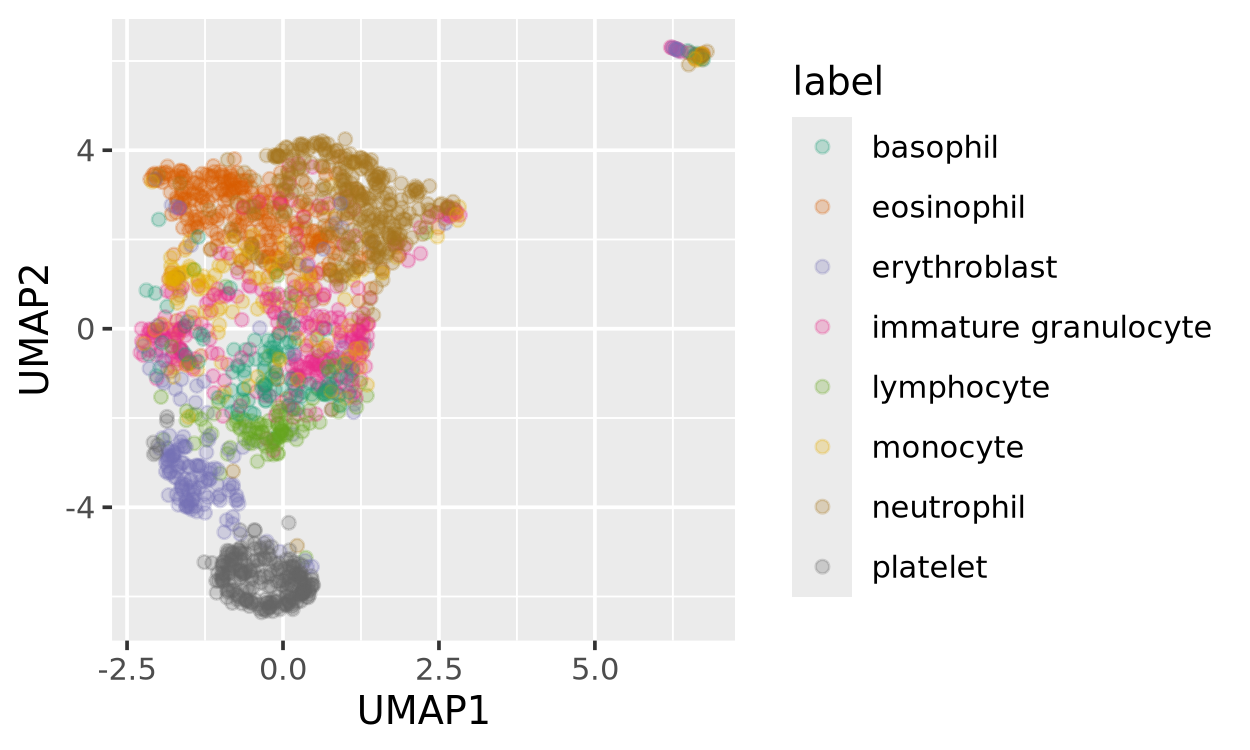

In [19]:
# Chart code goes here

umap_coords |>
    ggplot(aes(x=UMAP1, y=UMAP2, color = label)) + geom_point(alpha=0.25) + scale_color_brewer(palette = 'Dark2')

**Check:** do the cell types land in different places?

- Do you see clear groups? Are they perfectly separate?
- Which cell types are hard to tell apart?

A:
* I see some more defined groups, but many groups have a lot of overlap and even mostly separate groups like the platelets have some overlap with other cells like erythroblasts. The data has quite a lot of overlap among different cell types, and no perfectly clear and separate groups.
* Monocytes, immature granulocytes, lymphocytes, and basophils are pretty spread out and not really grouped together, though all cell types have some observations not located in the main cluster for their group.

## 4. Fit a random forest

Fit a random forest on `train`. Use the formula `label ~ .` (all the `dim_` columns are predictors).

```r
rand_forest(trees = 200) |> set_mode('classification') |> set_engine('ranger')
```

In [10]:
# Fit your model here

mod <- rand_forest(trees = 200) |> set_mode('classification') |> set_engine('ranger')

fit_mod = mod |> fit(label ~ ., data = train)

## 5. Evaluate on the test set

Find the accuracy of your model on `test`.

<details>
<summary>Hint: how do I find the accuracy?</summary>

1. `predict()` gives the predicted class for each test image.
2. `bind_cols()` puts it next to the true `label`.
3. `accuracy()` compares them.

```r
predict(fit, new_data = test) |>
    bind_cols(test) |>
    accuracy(truth = label, estimate = .pred_class)
```

Here `fit` is the name of your fitted model. Use your own name.

</details>

In [11]:
# Accuracy on the test set
predict(fit_mod, new_data = test) |>
    bind_cols(test) |>
    accuracy(truth = label, estimate = .pred_class)

  .metric  .estimator .estimate
1 accuracy multiclass 0.8276869

In [13]:
# Accuracy on the train set
predict(fit_mod, new_data = train) |>
    bind_cols(train) |>
    accuracy(truth = label, estimate = .pred_class)

  .metric  .estimator .estimate
1 accuracy multiclass 0.9994149

**Check:** with 8 types, guessing at random would get about 0.13. A good model gets about 0.80 to 0.85 on the test images. How does yours compare?

- Is the accuracy on `train` higher than on `test`? What does that tell you?

A: 
* Our model got 0.83, which is a good score on the test images for this data. However, compared to the train data, the score is much lower as the train data has an accuracy of ~1.0. This difference occurs because the model learns some random noise from the train data, and does not perfectly capture the pattern. However, because there are 8 types, this is still a pretty good performance.

## 6. Bonus: which cells does it mix up?

Accuracy is one number for all 8 types. A **confusion matrix** shows which types the model confuses.

Make one with `conf_mat()`, then look back at your UMAP. Do the types that overlap in the UMAP get mixed up by the model?

In [21]:
# Confusion matrix here
predict(fit_mod, new_data=test) |>
    bind_cols(test) |>
    conf_mat(truth = label, estimate = .pred_class)

                      Truth
Prediction             basophil eosinophil erythroblast immature granulocyte
  basophil                   69          0            0                    4
  eosinophil                  6        279            2                    7
  erythroblast                0          0          133                    0
  immature granulocyte       41          5            8                  249
  lymphocyte                  6          0            4                    4
  monocyte                    0          1            1                    5
  neutrophil                  1         20            2                   15
  platelet                    0          1            4                    0
                      Truth
Prediction             lymphocyte monocyte neutrophil platelet
  basophil                      6        1          0        0
  eosinophil                    6       12          7        0
  erythroblast                 18        0          1        8

*Your answer:* Which cell types does the model mix up? Why do you think so?

A: This model mixes up basophils, lymphocytes, and monocytes the most, but other cell types also have some misclassifications. This occurs because the vector representations for some cells are very similar, with no strictly defined groups or "bounds" for vector representation by group as seen in our visualization at the beginning of the exercise. 